In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from scipy.stats.contingency import association

clientFile = "../../data/clientes.csv"
raw = pd.read_csv(clientFile)

print(f"{raw.shape[0]:,} rows x {raw.shape[1]} feature columns, indexed by RecordID")
raw.head()

1,143 rows x 13 feature columns, indexed by RecordID


,customer_id,country_or_region,commercial_region,island,municipality,city,postal_area,postal_code,street,address,customer_type,company_name,customer_since_year
0,842570,Country CT11: Land of The Final Version,Region RG37: We Will See Later,NaN,NaN,City CY417: Missing Cell Port,NaN,Postal code PC828: #REF! Delivery Route,NaN,Address AD1120: Cell Without a Home,NaN,Excel Is Not A Database Ltd 150,2018
1,770941,Country CT9: Land of The Final Version,NaN,NaN,NaN,NaN,NaN,Postal code PC56: #REF! Delivery Route,NaN,Address AD62: Cell Without a Home,NaN,Excel Is Not A Database Ltd 1064,2021
2,827053,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC827: #REF! Delivery Route,Street ST170: PowerPoint New Walk,Address AD449: Cell Without a Home,NaN,Excel Is Not A Database Ltd 113,2016
3,494648,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC826: #REF! Delivery Route,NaN,Address AD454: Cell Without a Home,NaN,Excel Is Not A Database Ltd 430,2015
4,429291,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC826: #REF! Delivery Route,NaN,Address AD453: Cell Without a Home,NaN,Excel Is Not A Database Ltd 673,2015


---

### 2. Data Cleaning: Dropping the Fully Empty Column
We identified that the variable `customer_type` has 0 non-missing values out of 1,143 customers, so it is a completely empty column. Because it provides no predictive signal, it was removed from the customer dataset.

In [3]:
df_clean = raw.copy()

# 1. Remove the fully empty column
df_clean = df_clean.drop(columns=["customer_type"])

# 2. Verification of the removal of the column
print(raw.shape, "->", df_clean.shape)

(1143, 13) -> (1143, 12)


In [4]:
# A column distinct on more than half its rows identifies the row, not a
# property of it.
id_like = [c for c in raw.columns if raw[c].nunique() > 0.5 * len(raw)]
print(id_like)


['customer_id', 'postal_code', 'address', 'company_name']


---

### 2.2. Feature Type Separation & Exclusions
To prepare the customer table for the merge with `train.csv`/`test.csv` and for feature encoding, we divide its attributes into distinct functional groups:

1. **Excluded Features (identifiers):**
   * The customer key (`customer_id`) is kept in the table because it is the join key with `train.csv`/`test.csv`, but it is excluded from the predictors to prevent memorization of individual customers (*overfitting*).
   * Columns that are distinct on more than half of the rows (`company_name`, `address`, `postal_code`) identify the customer instead of describing it, so they are also excluded.
   * The empty column `customer_type` was already removed in the previous step.
   * This table has no target variable and no raw date strings: the target (`repeat_purchase_90d`) and `purchase_date` live in `train.csv`.

2. **Numeric Features (`numeric`):**
   * Dynamically selected numerical indicators. In this table this is only `customer_since_year`, which can later be turned into a customer seniority feature and scaled.

3. **Categorical Features (`categorical`):**
   * Dynamically identified non-numeric attributes (the geographic hierarchy: `country_or_region`, `commercial_region`, `island`, `municipality`, `city`, `postal_area`, `street`), designated for missing value imputation and categorical encoding (One-Hot for low cardinality / Frequency Encoding for high cardinality).

In [5]:
# Identifiers that MUST NOT be used for model training
# (customer_id stays in the table as the join key with train.csv/test.csv)
key = "customer_id"
id_like = [c for c in df_clean.columns if df_clean[c].nunique() > 0.5 * len(df_clean)]
identifiers = [key] + [c for c in id_like if c != key]

# Automatic separation between numerical and categorical variables
numeric = [
    c for c in df_clean.columns
    if c not in identifiers and pd.api.types.is_numeric_dtype(df_clean[c])
]

categorical = [
    c for c in df_clean.columns
    if c not in identifiers + numeric
]

# Validation Output
print(f"Total features: {df_clean.shape[1]} | Numeric: {len(numeric)} | Categorical: {len(categorical)}")
#print(df_clean[categorical].nunique().sort_values(ascending=False))

Total features: 12 | Numeric: 1 | Categorical: 7


**Conclusions:** Explicitly separating the customer key and raw identifiers (`customer_id`, `company_name`, `address`, `postal_code`) from the numerical and categorical features ensures strict adherence to machine learning best practices. `customer_id` is kept in the table only as the join key with `train.csv`/`test.csv`, while the remaining near-unique columns are excluded because they identify a customer rather than describe it. By isolating these non-predictive attributes before model training, we prevent the model from memorizing individual customers, avoid dimensionality inflation from high-cardinality identifiers, and guarantee that only valid, analytically sound predictors (`customer_since_year` and the geographic hierarchy) enter the feature matrix.

In [6]:
# Number of distinct levels per categorical feature, to choose the encoding
# (One-Hot for low cardinality / Frequency Encoding for high cardinality)
levels = raw[categorical].nunique().sort_values(ascending=False)
levels

street               511
city                 417
postal_area          271
municipality         183
commercial_region     37
country_or_region     11
island                10
dtype: int64

**Conclusions:** The cardinality of the categorical features varies widely, so a single encoding strategy is not suitable for all of them:

* **Low cardinality** (`island` with 10 levels and `country_or_region` with 11): these can be safely One-Hot encoded without a large increase in dimensionality. However, `country_or_region` is highly unbalanced (about 94% of customers belong to CT10), so most of its levels are rare and it may be more informative as a binary flag.
* **Medium cardinality** (`commercial_region` with 37 levels): One-Hot encoding is still feasible if rare regions are grouped into an `"Other"` category. Otherwise, Frequency Encoding is a more compact alternative.
* **High cardinality** (`municipality` with 183, `postal_area` with 271, `city` with 417 and `street` with 511 levels): One-Hot encoding would add hundreds of sparse columns for only 1,143 customers, which increases the risk of overfitting. These features should use Frequency Encoding or have their rare levels grouped. Since they form a geographic hierarchy, keeping only the more general levels may also be enough.

These counts were calculated before handling missing values. Imputing with categories such as `"Unknown"` will add one more level to the affected features.

---

### 2.3. Handling Structural Missing Values



#### 2.3.1. Missingness Diagnosis: Structural or Random?
Before filling anything, each geographic column's missingness flag is crossed with where the customer sits
in the geography. If a flag falls evenly across the groups, those values are missing at random; if it piles up on
some groups, the missingness has a structure, and a blind fill (e.g. the mode) would erase it.

* **Chi-square** measures the distance between observed counts and the counts of an evenly spread flag.
* **Cramér's V** rescales it to 0-1 (0 = spread as chance would spread it, 1 = the group fixes the flag completely), so it is the number to compare.
* **Minimum expected count**: below 5 the chi-square approximation is not reliable (hatched cells).

The 37 commercial regions are grouped into 4 region types, since 37 levels would leave most table cells with expected counts near zero.

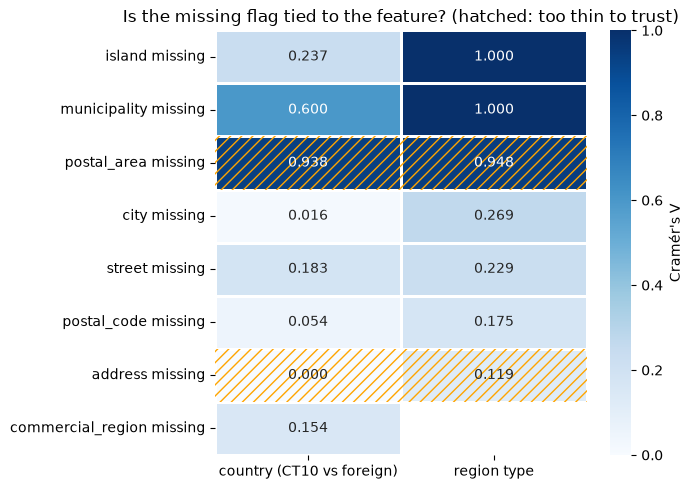

,island,municipality,postal_area,commercial_region,customers
region type,,,,,
"CT10, island region (RG17/RG29)",0.0,0.0,0.4,0.0,565
"CT10, no region",100.0,100.0,5.3,100.0,95
"CT10, other region",100.0,0.0,0.0,0.0,419
foreign,100.0,100.0,100.0,29.7,64


In [7]:
# Where does each customer sit in the geography? Four groups, defined from
# observed columns only. 37 raw regions would leave most cells of the table
# with expected counts near zero, so the regions are grouped by what they are.
is_ct10 = df_clean["country_or_region"].str.startswith("Country CT10:")
region_type = pd.Series(np.select(
    [~is_ct10,
     df_clean["commercial_region"].isna(),
     df_clean["commercial_region"].str.match(r"Region RG(17|29):", na=False)],
    ["foreign", "CT10, no region", "CT10, island region (RG17/RG29)"],
    default="CT10, other region"), index=df_clean.index, name="region type")

explanatory = pd.DataFrame({
    "country (CT10 vs foreign)": np.where(is_ct10, "CT10", "foreign"),
    "region type": region_type,
}, index=df_clean.index)

# One missingness flag per geographic column that has missing values
geo_cols = ["commercial_region", "island", "municipality", "postal_area",
            "postal_code", "city", "street", "address"]
missing_flags = {f"{c} missing": df_clean[c].isna() for c in geo_cols}

rows = []
for flag_name, flag in missing_flags.items():
    for feature in explanatory:
        # region type is built from commercial_region, so testing that column's
        # own missingness against it would be circular
        if flag_name == "commercial_region missing" and feature == "region type":
            continue
        table = pd.crosstab(flag, explanatory[feature])
        chi2, p, _, expected = chi2_contingency(table)
        rows.append({
            "missing flag": flag_name,
            "feature": feature,
            "n missing": int(flag.sum()),
            "chi2": chi2,
            "Cramer's V": association(table, method="cramer", correction=True),
            "p": p,
            "min expected count": expected.min(),
        })
association_table = pd.DataFrame(rows)

# One row per flag, one column per feature, coloured by V.
strength = association_table.pivot(index="missing flag", columns="feature", values="Cramer's V")
too_thin = association_table.pivot(index="missing flag", columns="feature",
                                   values="min expected count") < 5
order = strength["region type"].sort_values(ascending=False).index
strength, too_thin = strength.loc[order], too_thin.loc[order]

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(strength, vmin=0, vmax=1, annot=True, fmt=".3f", linewidths=2,
            cmap="Blues", cbar_kws={"label": "Cramér's V"}, ax=ax)
# Hatched where the minimum expected count is under 5: too thin to trust
for r, c in zip(*np.where(too_thin.values)):
    ax.add_patch(plt.Rectangle((c, r), 1, 1, fill=False, hatch="///",
                               edgecolor="orange", linewidth=0))
ax.set(xlabel="", ylabel="",
       title="Is the missing flag tied to the feature? (hatched: too thin to trust)")
plt.tight_layout()
plt.show()

# The same association read group by group: % of customers missing each column
missing_by_group = (df_clean[["island", "municipality", "postal_area", "commercial_region"]]
                    .isna().groupby(region_type).mean().mul(100).round(1)
                    .assign(customers=region_type.value_counts()))
missing_by_group

**Conclusions:** The missing values in `island`, `municipality` and `postal_area` are **structural, not random**.
Their flags are fixed by the region type: Cramér's V = **1.000** for `island` and `municipality`, and **0.948** for
`postal_area` (hatched, since it has only 71 missing values, but the group table shows the same pattern):

* `island` is missing for **100%** of customers outside the island regions RG17/RG29, and for **0%** inside them.
* `municipality` is missing for **100%** of foreign customers and of CT10 customers with no region, and for **0%** elsewhere.
* `postal_area` is missing for **100%** of foreign customers (64 of the 71 missing values).

These values do not exist for those customers, so they are filled with an explicit category in the next step.

`city`, `street` and `postal_code` show only a weak association (V between 0.17 and 0.27): there is no rule behind
them, so they are left open and handled inside each train split. The 95 CT10 customers with no `commercial_region`
are also left open: without the region we cannot tell whether their island is absent or simply unrecorded.

#### 2.3.2. Filling the Structural Missing Values
A structural missing value is not a lost value: it is a value that does not exist for that customer.
These are filled with an explicit category instead of being imputed:

* **Foreign customers** (outside CT10) have no `island`, `municipality` or `postal_area`, since these are CT10 divisions → `"(foreign)"`.
* **CT10 customers in a non-island region** (every region except RG17 and RG29) have no `island` → `"(mainland)"`.

The labels are written in parentheses, following the convention used in the course practicals (the "own level"
fill uses `"(missing)"`): it marks them as categories created during cleaning rather than values that came with the
data, and guarantees they can never coincide with a real level such as `"Island IS7: The Pivot Archipelago"`.

Since this is a fixed rule and not a statistic computed from the rows (like a mode or a median), it cannot leak
information from future test rows, so it is applied to the cleaned file. The 95 CT10 customers with no
`commercial_region` are **not** filled: without the region we cannot tell whether the island is absent or simply
unrecorded, so they stay missing and are handled inside each train split.

In [8]:
# Structural rules: a cell is filled only if it is empty AND the rule says the value cannot exist
foreign = ~df_clean["country_or_region"].str.startswith("Country CT10:")
island_region = df_clean["commercial_region"].str.match(r"Region RG(17|29):", na=False)
mainland = ~foreign & df_clean["commercial_region"].notna() & ~island_region

structural_rules = [
    # (rows, columns, label)
    (foreign,  ["island", "municipality", "postal_area"], "(foreign)"),
    (mainland, ["island"],                                "(mainland)"),
]

nulls_before = df_clean.isna().sum()
for rows, cols, label in structural_rules:
    for col in cols:
        df_clean.loc[rows & df_clean[col].isna(), col] = label

filled = nulls_before - df_clean.isna().sum()
pd.DataFrame({
    "nulls before": nulls_before,
    "filled (structural)": filled,
    "nulls left": df_clean.isna().sum(),
}).loc[lambda t: t["nulls before"] > 0]

,nulls before,filled (structural),nulls left
commercial_region,114,0,114
island,578,483,95
municipality,159,64,95
city,546,0,546
postal_area,71,64,7
postal_code,170,0,170
street,598,0,598
address,6,0,6


In [9]:
# 1. No real value was overwritten: every filled cell was empty in the raw file
for col in ["island", "municipality", "postal_area"]:
    new_labels = df_clean[col].isin(["(foreign)", "(mainland)"])
    assert raw.loc[new_labels, col].isna().all(), col

# 2. The island regions (RG17/RG29) never received "(mainland)"
assert not (island_region & (df_clean["island"] == "(mainland)")).any()

# 3. What is left in island/municipality is exactly the 95 CT10 customers with no region
assert df_clean.loc[df_clean["island"].isna(), "commercial_region"].isna().all()
assert df_clean.loc[df_clean["municipality"].isna(), "commercial_region"].isna().all()
print("All structural fill checks passed")

All structural fill checks passed


---

### 2.4. Saving the Cleaned Dataset
The cleaned table is saved at the end, once every cleaning step above has been applied. The remaining missing
values are left open on purpose: they are filled later, inside each train split, so that no statistic is computed
over rows that will be used for testing.

In [10]:
outputFile = "../../data/clientesDataset/clientes_clean.csv"
df_clean.to_csv(outputFile, index=False)

print(f"Dataset cleaned saved successfully to: {outputFile}")
print(f"{df_clean.shape[0]:,} rows x {df_clean.shape[1]} columns, "
      f"{df_clean.isna().sum().sum():,} missing values left open")

Dataset cleaned saved successfully to: ../../data/clientesDataset/clientes_clean.csv
1,143 rows x 12 columns, 1,631 missing values left open
